# 08 · Model comparison and statistical tests

Reads only the artifacts saved by notebooks 03–07 and writes the comparison tables, figures and `results/metrics/statistical_comparison.json`.

**What is compared.**
- **Threshold-free:** ROC-AUC and PR-AUC overall, and ROC-AUC of seen attacks vs normals and of unseen attacks vs normals. These compare *ranking* quality and are not affected by where each model happens to put its 0.5 threshold.
- **Matched FPR:** unseen recall at test FPR budgets of 1/2/5% (read off the test ROC curve), and at deployable thresholds calibrated on out-of-fold training normals.
- **Threshold 0.5:** the classic numbers, for continuity. FPRs differ between models here.
- **Seeds:** mean ± SD over the 5 end-to-end runs.

**Tests (primary seed).**
- McNemar (Edwards correction) on all 22,543 test rows and on the 3,750 unseen-attack rows. Two-sided: different errors, not which is better.
- Paired bootstrap (1,000 resamples of test rows, same rows for both models) of Δ Macro-F1, Δ unseen recall at 0.5, Δ ROC-AUC (unseen vs normal), and Δ unseen recall at matched 2% test FPR (threshold re-chosen inside each resample).
- Holm–Bonferroni over the whole family of two-sided tests.
- A cluster bootstrap that resamples the 17 unseen attack *types*, which shows how much unseen recall depends on which attack types happen to be in the test set.

In [1]:
import sys, json, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src.config import set_all_seeds
from src import controlled_framework as cf

rng = set_all_seeds(cf.SEED)
sns.set_theme(style="whitegrid", context="notebook")
print(f"primary seed={cf.SEED} | seeds={cf.SEEDS} | trials={cf.N_TRIALS} | novelty CV folds={cf.N_SPLITS} | "
      f"threshold={cf.THRESHOLD} | FPR budgets={cf.FPR_BUDGETS} | class_weight={cf.CLASS_WEIGHT}")

primary seed=42 | seeds=[42, 1, 2, 3, 4] | trials=25 | novelty CV folds=5 | threshold=0.5 | FPR budgets=[0.01, 0.02, 0.05] | class_weight=None


## 1. Load saved metrics and predictions

In [2]:
MODELS = {"Majority Baseline": "majority_baseline", "Logistic Regression": "logistic_regression",
          "Decision Tree": "decision_tree", "Random Forest": "random_forest", "XGBoost": "xgboost"}
LEARNED = [n for n in MODELS if n != "Majority Baseline"]
metrics = {n: json.loads((cf.METRICS_DIR / f"{k}.json").read_text()) for n, k in MODELS.items()}
preds = {n: pd.read_csv(cf.PRED_DIR / f"{k}_predictions.csv") for n, k in MODELS.items()}
y_true = preds["Logistic Regression"]["y_true"].to_numpy()
for n, p in preds.items():
    assert len(p) == 22543 and (p["y_true"].to_numpy() == y_true).all(), n
    cm = np.array(metrics[n]["overall_metrics"]["confusion_matrix"])
    assert cm[1, 1] == int(((p.y_true == 1) & (p.y_pred == 1)).sum()), n   # JSON and CSV agree
seed_metrics = {n: [metrics[n]] + [json.loads((cf.METRICS_DIR / "seeds" / f"{MODELS[n]}_seed{s}.json").read_text())
                                   for s in cf.SEEDS if s != cf.SEED] for n in LEARNED}
print("loaded:", list(MODELS), "| seeds per model:", {n: len(v) for n, v in seed_metrics.items()})

loaded: ['Majority Baseline', 'Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost'] | seeds per model: {'Logistic Regression': 5, 'Decision Tree': 5, 'Random Forest': 5, 'XGBoost': 5}


## 2. Primary-seed comparison tables

In [3]:
comparison = pd.DataFrame([cf.summary_row(metrics[n]) for n in MODELS])
comparison["best_novelty_cv_auc"] = [metrics[n]["hyperparameters"].get("best_novelty_cv_auc", np.nan) for n in MODELS]
cf.save_table(comparison, "model_comparison")
main_cols = ["model", "roc_auc", "pr_auc", "auc_seen_vs_normal", "auc_unseen_vs_normal",
             "unseen_recall@test_fpr_1pct", "unseen_recall@test_fpr_2pct", "unseen_recall@test_fpr_5pct",
             "macro_f1", "false_positive_rate", "seen_recall", "unseen_recall", "generalization_drop_pp"]
headline = comparison[main_cols]
cf.save_table(headline, "headline_comparison")
display(headline.set_index("model").T)

model,Majority Baseline,Logistic Regression,Decision Tree,Random Forest,XGBoost
roc_auc,0.500000,0.884761,0.884255,0.965389,0.958148
pr_auc,0.569268,0.915645,0.911465,0.968371,0.965966
auc_seen_vs_normal,0.500000,0.885431,0.946450,0.975175,0.962921
auc_unseen_vs_normal,0.500000,0.883139,0.733611,0.941684,0.946587
unseen_recall@test_fpr_1pct,0.000000,0.052267,0.066667,0.071733,0.051467
unseen_recall@test_fpr_2pct,0.000000,0.053867,0.145867,0.093067,0.079467
unseen_recall@test_fpr_5pct,0.000000,0.072000,0.356267,0.633333,0.821600
macro_f1,0.301057,0.735835,0.779882,0.768281,0.781162
false_positive_rate,0.000000,0.072400,0.029866,0.027188,0.025747
seen_recall,0.000000,0.715200,0.755800,0.767900,0.782100


In [4]:
dep = pd.DataFrame([{"model": n, "budget": k, **v} for n in LEARNED for k, v in metrics[n]["deployable_operating_points"].items()])
cf.save_table(dep, "deployable_operating_points")
display(dep.pivot(index="model", columns="budget", values=["fpr", "unseen_recall", "seen_recall"]).round(4))

fpr                   unseen_recall           \
budget              fpr_1pct fpr_2pct fpr_5pct      fpr_1pct fpr_2pct   
model                                                                   
Decision Tree         0.0299   0.0391   0.0596        0.3496   0.3507   
Logistic Regression   0.0668   0.0719   0.0804        0.2107   0.2875   
Random Forest         0.0990   0.1125   0.1348        0.8787   0.9253   
XGBoost               0.0329   0.0452   0.1054        0.6003   0.7312   

                             seen_recall                    
budget              fpr_5pct    fpr_1pct fpr_2pct fpr_5pct  
model                                                       
Decision Tree         0.5741      0.7558   0.7969   0.8986  
Logistic Regression   0.4325      0.6953   0.7131   0.7539  
Random Forest         0.9555      0.8961   0.9488   0.9913  
XGBoost               0.8469      0.8488   0.8553   0.8641

In [5]:
strat = pd.DataFrame([{"model": n, "category": c, "seen_n": v["seen"]["total_samples"], "seen_recall": v["seen"]["recall"],
                       "unseen_n": v["unseen"]["total_samples"], "unseen_recall": v["unseen"]["recall"]}
                      for n in LEARNED for c, v in metrics[n]["category_stratified_seen_unseen_recall"].items()])
cf.save_table(strat, "category_stratified_seen_unseen")
gaps = comparison.set_index("model").loc[LEARNED, ["generalization_drop_pp", "reweighted_drop_pp", "unseen_recall", "unseen_macro_recall"]]
cf.save_table(gaps.reset_index(), "composition_reweighted_gap")
display(strat.pivot(index="category", columns="model", values=["seen_recall", "unseen_recall"]).round(3)); display(gaps)

seen_recall                                            \
model    Decision Tree Logistic Regression Random Forest XGBoost   
category                                                           
DoS              0.997               0.934         0.997   0.998   
Probe            0.997               0.965         1.000   0.999   
R2L              0.016               0.026         0.066   0.122   
U2R              0.000               0.243         0.054   0.054   

         unseen_recall                                            
model    Decision Tree Logistic Regression Random Forest XGBoost  
category                                                          
DoS              0.042               0.180         0.116   0.091  
Probe            0.852               0.599         0.542   0.666  
R2L              0.166               0.010         0.007   0.038  
U2R              0.167               0.133         0.167   0.133

,generalization_drop_pp,reweighted_drop_pp,unseen_recall,unseen_macro_recall
model,,,,
Logistic Regression,41.97,47.72,0.2955,0.1547
Decision Tree,40.62,45.98,0.3496,0.3031
Random Forest,52.18,57.35,0.2461,0.2002
XGBoost,49.89,54.69,0.2832,0.2034


In [6]:
per_attack = pd.DataFrame({"attack": list(metrics["Logistic Regression"]["per_unseen_attack_recall"])})
per_attack["category"] = [metrics["Logistic Regression"]["per_unseen_attack_recall"][a]["category"] for a in per_attack.attack]
per_attack["n"] = [metrics["Logistic Regression"]["per_unseen_attack_recall"][a]["total_samples"] for a in per_attack.attack]
for n in LEARNED:
    per_attack[f"{n} recall@0.5"] = [metrics[n]["per_unseen_attack_recall"][a]["recall"] for a in per_attack.attack]
per_attack = per_attack.sort_values("n", ascending=False)
cf.save_table(per_attack, "per_unseen_attack_recall_all_models")
per_attack

,attack,category,n,Logistic Regression recall@0.5,Decision Tree recall@0.5,Random Forest recall@0.5,XGBoost recall@0.5
3,mscan,Probe,996,0.4869,0.8092,0.3996,0.5663
0,apache2,DoS,737,0.1913,0.0787,0.2619,0.0000
5,processtable,DoS,685,0.2453,0.0175,0.0073,0.2248
10,snmpguess,R2L,331,0.0091,0.0000,0.0000,0.0000
7,saint,Probe,319,0.9498,0.9843,0.9875,0.9781
2,mailbomb,DoS,293,0.0000,0.0000,0.0000,0.0000
9,snmpgetattack,R2L,178,0.0000,0.0000,0.0000,0.0000
1,httptunnel,R2L,133,0.0000,0.8271,0.0150,0.1654
4,named,R2L,17,0.1176,0.2353,0.1176,0.2353
6,ps,U2R,15,0.0000,0.2000,0.1333,0.1333


## 3. Seed variation (5 end-to-end runs per model)

In [7]:
KEYS = ["best_novelty_cv_auc", "roc_auc", "auc_seen_vs_normal", "auc_unseen_vs_normal", "unseen_recall@test_fpr_2pct",
        "unseen_recall@oof_fpr_2pct", "test_fpr@oof_fpr_2pct", "macro_f1", "false_positive_rate", "unseen_recall"]
seed_rows = []
for n in LEARNED:
    for m in seed_metrics[n]:
        r = cf.summary_row(m); r["best_novelty_cv_auc"] = m["hyperparameters"]["best_novelty_cv_auc"]; r["seed"] = m["seed"]
        seed_rows.append({"model": n, "seed": m["seed"], **{k: r[k] for k in KEYS}})
seed_df = pd.DataFrame(seed_rows)
cf.save_table(seed_df, "all_models_seeds")
agg = seed_df.groupby("model")[KEYS].agg(["mean", "std"]).loc[LEARNED]
agg.columns = [f"{a} ({b})" for a, b in agg.columns]
cf.save_table(agg.reset_index(), "seed_summary")
display(agg.T.round(4))

model,Logistic Regression,Decision Tree,Random Forest,XGBoost
best_novelty_cv_auc (mean),0.9054,0.9113,0.9926,0.9853
best_novelty_cv_auc (std),0.0007,0.0065,0.0019,0.0028
roc_auc (mean),0.8850,0.8878,0.9648,0.9610
roc_auc (std),0.0006,0.0089,0.0014,0.0044
auc_seen_vs_normal (mean),0.8857,0.9465,0.9747,0.9684
auc_seen_vs_normal (std),0.0009,0.0012,0.0007,0.0050
auc_unseen_vs_normal (mean),0.8831,0.7456,0.9410,0.9432
auc_unseen_vs_normal (std),0.0001,0.0277,0.0037,0.0048
unseen_recall@test_fpr_2pct (mean),0.0539,0.1657,0.0838,0.0689
unseen_recall@test_fpr_2pct (std),0.0003,0.0473,0.0142,0.0138


In [8]:
import itertools
PAIRS = list(itertools.combinations(LEARNED, 2))
key = lambda a, b: f"{cf.file_key(a)}_vs_{cf.file_key(b)}"
seed_pairs = []
for a, b in PAIRS:
    A = seed_df[seed_df.model == a].set_index("seed"); B = seed_df[seed_df.model == b].set_index("seed")
    for k in ["auc_unseen_vs_normal", "unseen_recall@test_fpr_2pct", "unseen_recall"]:
        d = (A[k] - B[k]).dropna()
        seed_pairs.append({"pair": key(a, b), "metric": k, "mean_diff": d.mean(), "sd_diff": d.std(),
                           "a_wins": int((d > 0).sum()), "n_seeds": len(d)})
seed_pairs = pd.DataFrame(seed_pairs)
cf.save_table(seed_pairs, "seed_paired_differences")
seed_pairs

,pair,metric,mean_diff,sd_diff,a_wins,n_seeds
0,logistic_regression_vs_decision_tree,auc_unseen_vs_normal,0.137514,0.027706,5,5
1,logistic_regression_vs_decision_tree,unseen_recall@test_fpr_2pct,-0.111733,0.047130,0,5
2,logistic_regression_vs_decision_tree,unseen_recall,-0.014260,0.087162,1,5
3,logistic_regression_vs_random_forest,auc_unseen_vs_normal,-0.057892,0.003633,0,5
4,logistic_regression_vs_random_forest,unseen_recall@test_fpr_2pct,-0.029920,0.014037,0,5
5,logistic_regression_vs_random_forest,unseen_recall,0.046840,0.010210,5,5
6,logistic_regression_vs_xgboost,auc_unseen_vs_normal,-0.060030,0.004823,0,5
7,logistic_regression_vs_xgboost,unseen_recall@test_fpr_2pct,-0.014933,0.014001,2,5
8,logistic_regression_vs_xgboost,unseen_recall,-0.027220,0.053355,3,5
9,decision_tree_vs_random_forest,auc_unseen_vs_normal,-0.195407,0.028769,0,5


## 4. Statistical tests (primary seed)

In [9]:
unseen_mask = preds["Logistic Regression"]["is_unseen"].to_numpy() & (y_true == 1)
mcnemar_full = {key(a, b): cf.compute_mcnemar_test(y_true, preds[a].y_pred.to_numpy(), preds[b].y_pred.to_numpy()) for a, b in PAIRS}
mcnemar_unseen = {key(a, b): cf.compute_mcnemar_test(y_true[unseen_mask], preds[a].y_pred.to_numpy()[unseen_mask],
                                                     preds[b].y_pred.to_numpy()[unseen_mask]) for a, b in PAIRS}
paired = {key(a, b): cf.compute_paired_bootstrap(preds[a], preds[b]) for a, b in PAIRS}
boot = {cf.file_key(n): cf.compute_bootstrap_cis(preds[n]) for n in LEARNED}
cluster = {cf.file_key(n): cf.compute_cluster_bootstrap_unseen(preds[n]) for n in LEARNED}

ci_rows = []
for n in LEARNED:
    k = cf.file_key(n)
    ci_rows.append({"model": n, "unseen_recall": metrics[n]["seen_vs_unseen_recall"]["unseen_recall"],
                    "row_bootstrap_ci": f"[{boot[k]['unseen_recall']['ci_95_lower']}, {boot[k]['unseen_recall']['ci_95_upper']}]",
                    "attack_type_cluster_ci": f"[{cluster[k]['unseen_recall_micro']['ci_95_lower']}, {cluster[k]['unseen_recall_micro']['ci_95_upper']}]",
                    "macro_over_types": metrics[n]["seen_vs_unseen_recall"]["unseen_macro_recall_over_types"],
                    "macro_cluster_ci": f"[{cluster[k]['unseen_recall_macro']['ci_95_lower']}, {cluster[k]['unseen_recall_macro']['ci_95_upper']}]"})
ci_tbl = pd.DataFrame(ci_rows)
cf.save_table(ci_tbl, "unseen_recall_confidence_intervals")
ci_tbl

,model,unseen_recall,row_bootstrap_ci,attack_type_cluster_ci,macro_over_types,macro_cluster_ci
0,Logistic Regression,0.2955,"[0.281, 0.3105]","[0.0892, 0.4906]",0.1547,"[0.0589, 0.2777]"
1,Decision Tree,0.3496,"[0.3348, 0.3648]","[0.0478, 0.6682]",0.3031,"[0.1183, 0.5177]"
2,Random Forest,0.2461,"[0.2321, 0.2597]","[0.011, 0.4651]",0.2002,"[0.0748, 0.3619]"
3,XGBoost,0.2832,"[0.2687, 0.298]","[0.0236, 0.5228]",0.2034,"[0.07, 0.3738]"


In [10]:
family = ([("mcnemar_full", k, v, v["p_value"]) for k, v in mcnemar_full.items()] +
          [("mcnemar_unseen", k, v, v["p_value"]) for k, v in mcnemar_unseen.items()] +
          [(f"paired_bootstrap:{m}", k, v[m], v[m]["p_two_sided"]) for k, v in paired.items() for m in v])
adj = cf.holm_adjust([f[3] for f in family])
rows = []
for (test, pair, d, p), pa in zip(family, adj):
    d["p_holm"] = float(pa); d["significant_holm_05"] = bool(pa < cf.ALPHA)
    rows.append({"test": test, "pair": pair, "p_raw": p, "p_holm": pa, "significant_holm_05": pa < cf.ALPHA,
                 "effect": d.get("statistic", d.get("mean")),
                 "ci_95": f"[{d['ci_95_lower']}, {d['ci_95_upper']}]" if "ci_95_lower" in d else ""})
tests_tbl = pd.DataFrame(rows)
cf.save_table(tests_tbl, "hypothesis_tests", floatfmt="{:.3g}")
print(f"{len(family)} two-sided tests, Holm-corrected")
tests_tbl

36 two-sided tests, Holm-corrected


,test,pair,p_raw,p_holm,significant_holm_05,effect,ci_95
0,mcnemar_full,logistic_regression_vs_decision_tree,7.311419e-122,2.558997e-120,True,551.0848,
1,mcnemar_full,logistic_regression_vs_random_forest,3.051552e-64,1.037528e-62,True,286.3838,
2,mcnemar_full,logistic_regression_vs_xgboost,1.207065e-131,4.345435e-130,True,596.0557,
3,mcnemar_full,decision_tree_vs_random_forest,6.280113e-15,1.884034e-13,True,60.8118,
4,mcnemar_full,decision_tree_vs_xgboost,3.227161e-01,6.116942e-01,False,0.9779,
5,mcnemar_full,random_forest_vs_xgboost,6.286738e-24,1.948889e-22,True,101.7539,
6,mcnemar_unseen,logistic_regression_vs_decision_tree,1.572002e-13,4.558806e-12,True,54.4780,
7,mcnemar_unseen,logistic_regression_vs_random_forest,1.419021e-10,3.973259e-09,True,41.1373,
8,mcnemar_unseen,logistic_regression_vs_xgboost,6.709696e-02,4.337831e-01,False,3.3526,
9,mcnemar_unseen,decision_tree_vs_random_forest,2.601998e-42,8.586594e-41,True,185.8176,


In [11]:
stat = {
    "framework": "ES335 controlled comparison (notebooks/08_evaluation_comparison.ipynb)",
    "evaluation_note": ("Primary seed (42). Threshold-free and matched-FPR comparisons are the primary evidence; "
                        "threshold-0.5 numbers are kept for continuity (FPRs differ there). Row bootstrap CIs cover "
                        "test-row sampling only; the cluster bootstrap resamples the 17 unseen attack types. "
                        f"Holm-Bonferroni over {len(family)} two-sided tests. Seed variation is in seed_summary / all_models_seeds tables."),
    "n_bootstraps": cf.N_BOOTSTRAPS, "alpha": cf.ALPHA, "multiple_comparison": "holm", "matched_fpr": cf.MATCHED_FPR,
    "mcnemar_tests_full_test_set": mcnemar_full,
    "mcnemar_tests_unseen_attacks": mcnemar_unseen,
    "paired_bootstrap_differences": paired,
    "bootstrap_95_confidence_intervals": boot,
    "cluster_bootstrap_unseen_recall": cluster,
    "seed_summary": {n: {k: {"mean": float(seed_df[seed_df.model == n][k].mean()), "std": float(seed_df[seed_df.model == n][k].std())}
                         for k in KEYS} for n in LEARNED},
}
(cf.METRICS_DIR / "statistical_comparison.json").write_text(json.dumps(stat, indent=2))
print("saved results/metrics/statistical_comparison.json")

saved results/metrics/statistical_comparison.json


## 5. Figures (`results/figures/evaluation/`)

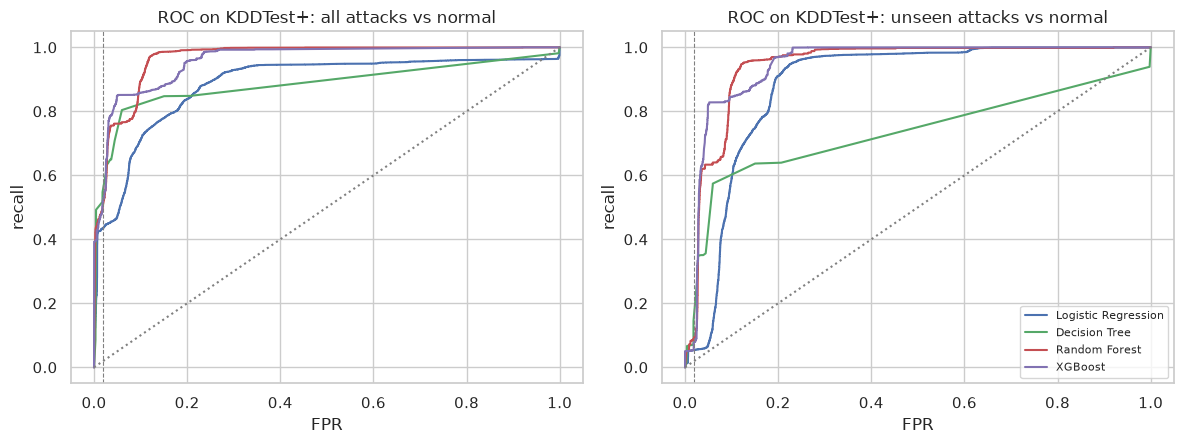

In [12]:
COLORS = {"Majority Baseline": "#9AA0A6", "Logistic Regression": "#4C72B0", "Decision Tree": "#55A868",
          "Random Forest": "#C44E52", "XGBoost": "#8172B2"}
from sklearn.metrics import roc_curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for n in LEARNED:
    p = preds[n]
    for ax, mask in [(axes[0], np.ones(len(p), bool)), (axes[1], ((p.y_true == 0) | p.is_unseen).to_numpy())]:
        fpr, tpr, _ = roc_curve(p.y_true[mask], p.y_prob[mask])
        ax.plot(fpr, tpr, color=COLORS[n], label=n)
for ax, t in zip(axes, ["all attacks vs normal", "unseen attacks vs normal"]):
    ax.plot([0, 1], [0, 1], ":", color="grey"); ax.set_xlabel("FPR"); ax.set_ylabel("recall"); ax.set_title(f"ROC on KDDTest+: {t}")
    ax.axvline(cf.MATCHED_FPR, color="grey", lw=.8, ls="--")
axes[1].legend(fontsize=8)
fig.tight_layout(); cf.save_figure(fig, "evaluation", "01_roc_curves"); plt.show()

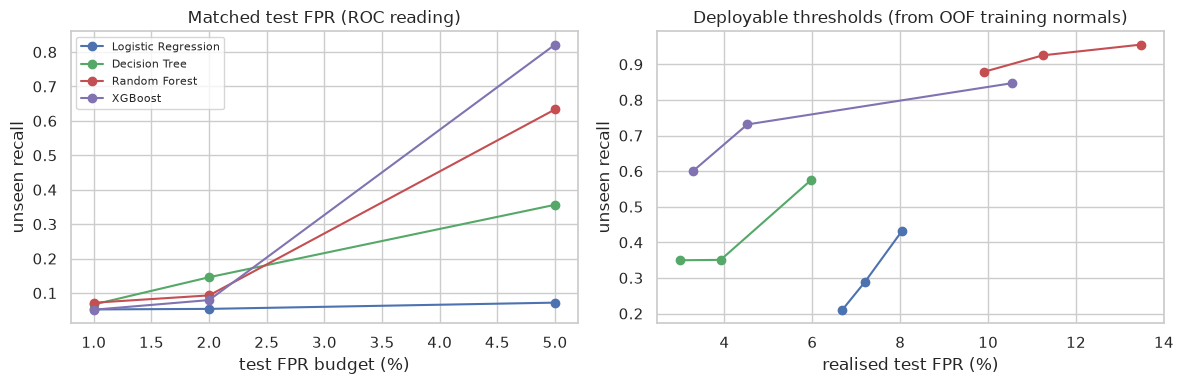

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
budgets = [cf.budget_key(b) for b in cf.FPR_BUDGETS]
for n in LEARNED:
    axes[0].plot([b * 100 for b in cf.FPR_BUDGETS], [metrics[n]["test_roc_operating_points"][k]["unseen_recall"] for k in budgets],
                 "o-", color=COLORS[n], label=n)
    d = metrics[n]["deployable_operating_points"]
    axes[1].plot([d[k]["fpr"] * 100 for k in budgets], [d[k]["unseen_recall"] for k in budgets], "o-", color=COLORS[n], label=n)
axes[0].set_xlabel("test FPR budget (%)"); axes[0].set_ylabel("unseen recall"); axes[0].set_title("Matched test FPR (ROC reading)")
axes[1].set_xlabel("realised test FPR (%)"); axes[1].set_ylabel("unseen recall"); axes[1].set_title("Deployable thresholds (from OOF training normals)")
axes[0].legend(fontsize=8); fig.tight_layout(); cf.save_figure(fig, "evaluation", "02_unseen_recall_at_fpr"); plt.show()

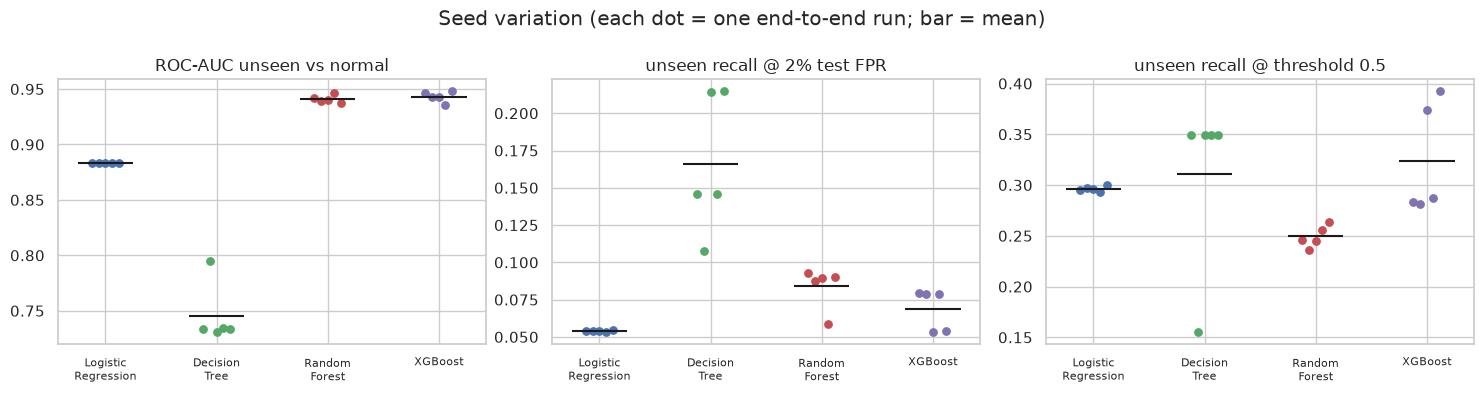

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k, t in [(axes[0], "auc_unseen_vs_normal", "ROC-AUC unseen vs normal"),
                 (axes[1], "unseen_recall@test_fpr_2pct", "unseen recall @ 2% test FPR"),
                 (axes[2], "unseen_recall", "unseen recall @ threshold 0.5")]:
    for i, n in enumerate(LEARNED):
        v = seed_df[seed_df.model == n][k]
        ax.scatter(np.full(len(v), i) + np.linspace(-.12, .12, len(v)), v, color=COLORS[n], s=28)
        ax.hlines(v.mean(), i - .25, i + .25, color="k", lw=1.5)
    ax.set_xticks(range(len(LEARNED)), [n.replace(" ", "\n") for n in LEARNED], fontsize=8); ax.set_title(t)
fig.suptitle("Seed variation (each dot = one end-to-end run; bar = mean)"); fig.tight_layout()
cf.save_figure(fig, "evaluation", "03_seed_variation"); plt.show()

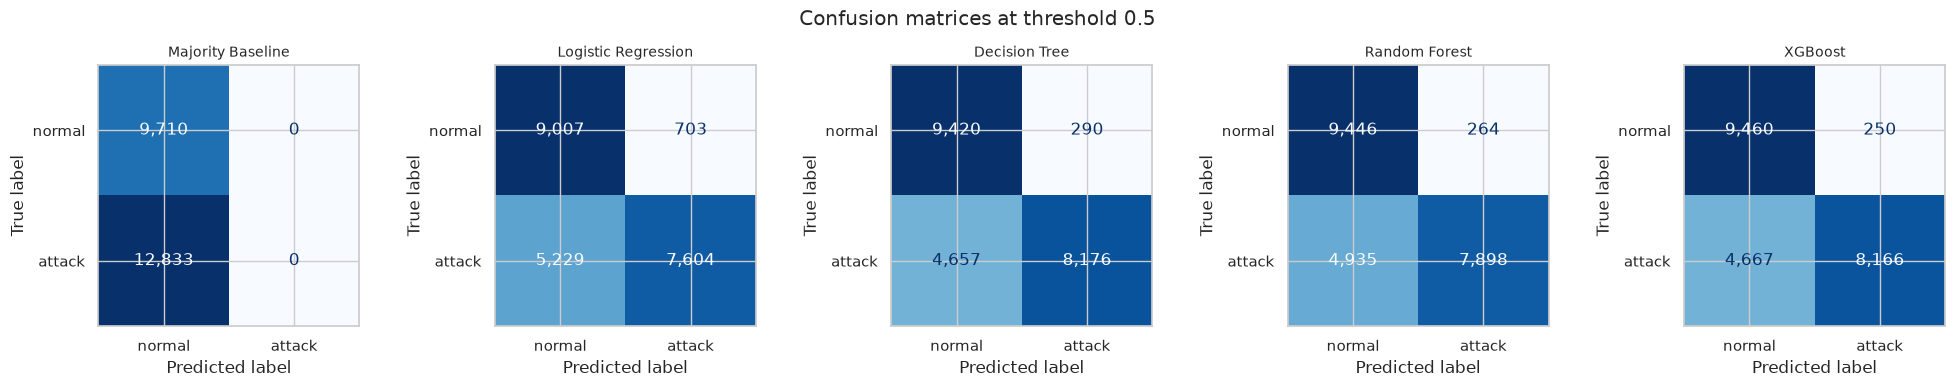

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, len(MODELS), figsize=(4 * len(MODELS), 3.8))
for ax, n in zip(axes, MODELS):
    ConfusionMatrixDisplay(np.array(metrics[n]["overall_metrics"]["confusion_matrix"]), display_labels=["normal", "attack"]).plot(
        ax=ax, cmap="Blues", values_format=",d", colorbar=False)
    ax.set_title(n, fontsize=10)
fig.suptitle("Confusion matrices at threshold 0.5"); fig.tight_layout()
cf.save_figure(fig, "evaluation", "04_confusion_matrices"); plt.show()

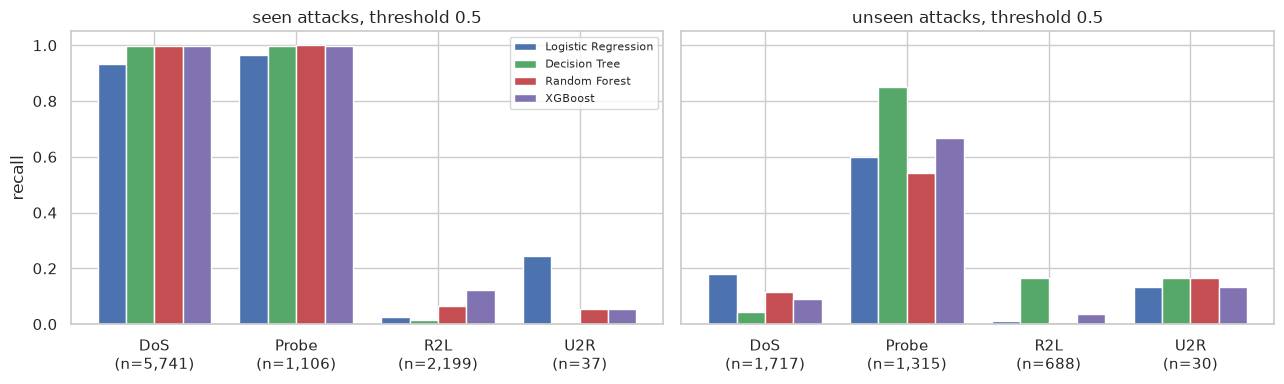

In [16]:
cats = cf.ATTACK_CATEGORIES
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
w = 0.8 / len(LEARNED)
for ax, part in zip(axes, ["seen", "unseen"]):
    for i, n in enumerate(LEARNED):
        s = metrics[n]["category_stratified_seen_unseen_recall"]
        ax.bar(np.arange(4) + (i - (len(LEARNED) - 1) / 2) * w, [s[c][part]["recall"] for c in cats], w, color=COLORS[n], label=n)
    s0 = metrics["Decision Tree"]["category_stratified_seen_unseen_recall"]
    ax.set_xticks(range(4), [f"{c}\n(n={s0[c][part]['total_samples']:,})" for c in cats]); ax.set_title(f"{part} attacks, threshold 0.5")
axes[0].set_ylabel("recall"); axes[0].legend(fontsize=8)
fig.tight_layout(); cf.save_figure(fig, "evaluation", "05_category_stratified_recall"); plt.show()

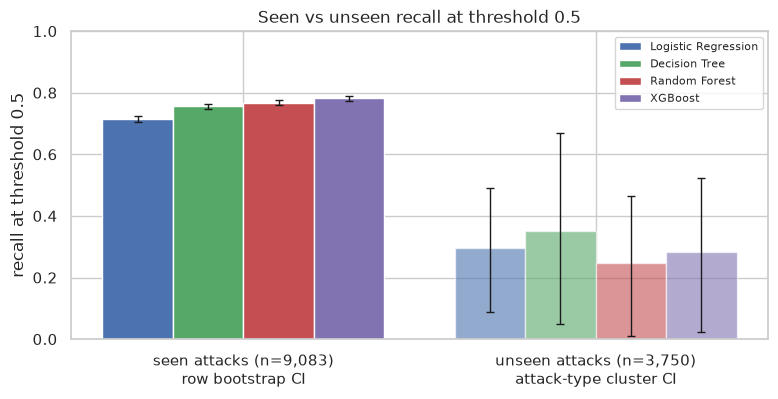

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
w = 0.8 / len(LEARNED)
for i, n in enumerate(LEARNED):
    k = cf.file_key(n); x = (i - (len(LEARNED) - 1) / 2) * w
    for j, part in enumerate(["seen_recall", "unseen_recall"]):
        v = metrics[n]["seen_vs_unseen_recall"][part]
        ci = boot[k][part] if part == "seen_recall" else cluster[k]["unseen_recall_micro"]
        ax.bar(j + x, v, w, color=COLORS[n], alpha=1 if j == 0 else .6, label=n if j == 0 else None)
        ax.errorbar(j + x, v, yerr=[[v - ci["ci_95_lower"]], [ci["ci_95_upper"] - v]], color="k", capsize=3, lw=1)
ax.set_xticks([0, 1], ["seen attacks (n=9,083)\nrow bootstrap CI", "unseen attacks (n=3,750)\nattack-type cluster CI"])
ax.set_ylim(0, 1); ax.set_ylabel("recall at threshold 0.5"); ax.legend(fontsize=8)
ax.set_title("Seen vs unseen recall at threshold 0.5")
cf.save_figure(fig, "evaluation", "06_seen_vs_unseen_generalization"); plt.show()

## 6. Summary (generated from the saved results)

In [18]:
c = comparison.set_index("model")
lines = ["**Primary seed (42), KDDTest+:**", ""]
for n in LEARNED:
    r = c.loc[n]
    lines.append(f"- **{n}**: unseen-vs-normal AUC {r.auc_unseen_vs_normal:.4f}, unseen recall @2% test FPR {100*r['unseen_recall@test_fpr_2pct']:.1f}%, "
                 f"seen-vs-normal AUC {r.auc_seen_vs_normal:.4f}; at 0.5: FPR {100*r.false_positive_rate:.2f}%, unseen recall {100*r.unseen_recall:.1f}%")
lines += ["", "**Across 5 seeds (mean ± SD):**", ""]
for n in LEARNED:
    s = seed_df[seed_df.model == n]
    lines.append(f"- **{n}**: unseen-vs-normal AUC {s.auc_unseen_vs_normal.mean():.4f} ± {s.auc_unseen_vs_normal.std():.4f}; "
                 f"unseen recall @2% test FPR {100*s['unseen_recall@test_fpr_2pct'].mean():.1f}% ± {100*s['unseen_recall@test_fpr_2pct'].std():.1f}")
sig = tests_tbl[tests_tbl.test == "paired_bootstrap:auc_unseen_vs_normal"][["pair", "effect", "ci_95", "p_holm"]]
lines += ["", "**Paired bootstrap Δ AUC (unseen vs normal), Holm-adjusted p:**", ""]
lines += [f"- {p}: {e:+.4f} {ci}, p_holm = {q:.3g}" for p, e, ci, q in sig.itertuples(index=False)]
summary_md = "\n".join(lines)
(cf.TABLES_DIR / "summary.md").write_text(summary_md + "\n")
display(Markdown(summary_md))

**Primary seed (42), KDDTest+:**

- **Logistic Regression**: unseen-vs-normal AUC 0.8831, unseen recall @2% test FPR 5.4%, seen-vs-normal AUC 0.8854; at 0.5: FPR 7.24%, unseen recall 29.5%
- **Decision Tree**: unseen-vs-normal AUC 0.7336, unseen recall @2% test FPR 14.6%, seen-vs-normal AUC 0.9465; at 0.5: FPR 2.99%, unseen recall 35.0%
- **Random Forest**: unseen-vs-normal AUC 0.9417, unseen recall @2% test FPR 9.3%, seen-vs-normal AUC 0.9752; at 0.5: FPR 2.72%, unseen recall 24.6%
- **XGBoost**: unseen-vs-normal AUC 0.9466, unseen recall @2% test FPR 7.9%, seen-vs-normal AUC 0.9629; at 0.5: FPR 2.57%, unseen recall 28.3%

**Across 5 seeds (mean ± SD):**

- **Logistic Regression**: unseen-vs-normal AUC 0.8831 ± 0.0001; unseen recall @2% test FPR 5.4% ± 0.0
- **Decision Tree**: unseen-vs-normal AUC 0.7456 ± 0.0277; unseen recall @2% test FPR 16.6% ± 4.7
- **Random Forest**: unseen-vs-normal AUC 0.9410 ± 0.0037; unseen recall @2% test FPR 8.4% ± 1.4
- **XGBoost**: unseen-vs-normal AUC 0.9432 ± 0.0048; unseen recall @2% test FPR 6.9% ± 1.4

**Paired bootstrap Δ AUC (unseen vs normal), Holm-adjusted p:**

- logistic_regression_vs_decision_tree: +0.1495 [0.1396, 0.1598], p_holm = 0.026
- logistic_regression_vs_random_forest: -0.0586 [-0.0626, -0.0545], p_holm = 0.026
- logistic_regression_vs_xgboost: -0.0635 [-0.0676, -0.0595], p_holm = 0.026
- decision_tree_vs_random_forest: -0.2081 [-0.2177, -0.1981], p_holm = 0.026
- decision_tree_vs_xgboost: -0.2130 [-0.2228, -0.2028], p_holm = 0.026
- random_forest_vs_xgboost: -0.0049 [-0.0071, -0.0028], p_holm = 0.026